# LeetCode #310: Minimum Height Trees

https://leetcode.com/problems/minimum-height-trees/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Topological Peeling (Leaf Removal) ★ | O(n) | O(n) |
| BFS from Every Node | O(n²) | O(n) |

## Understanding the Methods
### Topological Peeling (Optimal)
Repeatedly remove all leaf nodes (degree 1) from the tree. The remaining 1 or 2 nodes are the roots that minimize tree height. This works because the center of a tree (its centroid) minimizes the maximum distance to any other node. Each round of peeling reduces the tree inward.

### BFS from Every Node
Compute the height of the tree rooted at each node using BFS. Return nodes with minimum height. Correct but O(n²) makes it impractical for large inputs.

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<int> FindMinHeightTrees(int n, int[][] edges) {
        if (n == 1) return new List<int> { 0 };
        var adj = new HashSet<int>[n];
        for (int i = 0; i < n; i++) adj[i] = new HashSet<int>();
        foreach (var e in edges) {
            adj[e[0]].Add(e[1]);
            adj[e[1]].Add(e[0]);
        }

        var leaves = new Queue<int>();
        for (int i = 0; i < n; i++)
            if (adj[i].Count == 1) leaves.Enqueue(i);

        int remaining = n;
        while (remaining > 2) {
            int size = leaves.Count;
            remaining -= size;
            for (int i = 0; i < size; i++) {
                int leaf = leaves.Dequeue();
                foreach (int nei in adj[leaf]) {
                    adj[nei].Remove(leaf);
                    if (adj[nei].Count == 1) leaves.Enqueue(nei);
                }
            }
        }
        return leaves.ToList();
    }
}

### Python

In [ ]:
from collections import deque

class Solution:
    def findMinHeightTrees(self, n: int, edges: list[list[int]]) -> list[int]:
        if n == 1:
            return [0]
        adj = [set() for _ in range(n)]
        for u, v in edges:
            adj[u].add(v)
            adj[v].add(u)

        leaves = deque(i for i in range(n) if len(adj[i]) == 1)
        remaining = n
        while remaining > 2:
            size = len(leaves)
            remaining -= size
            for _ in range(size):
                leaf = leaves.popleft()
                for nei in adj[leaf]:
                    adj[nei].remove(leaf)
                    if len(adj[nei]) == 1:
                        leaves.append(nei)
        return list(leaves)

### Go

In [ ]:
func findMinHeightTrees(n int, edges [][]int) []int {
    if n == 1 {
        return []int{0}
    }
    adj := make([]map[int]bool, n)
    for i := range adj {
        adj[i] = map[int]bool{}
    }
    for _, e := range edges {
        adj[e[0]][e[1]] = true
        adj[e[1]][e[0]] = true
    }

    leaves := []int{}
    for i := 0; i < n; i++ {
        if len(adj[i]) == 1 {
            leaves = append(leaves, i)
        }
    }

    remaining := n
    for remaining > 2 {
        remaining -= len(leaves)
        newLeaves := []int{}
        for _, leaf := range leaves {
            for nei := range adj[leaf] {
                delete(adj[nei], leaf)
                if len(adj[nei]) == 1 {
                    newLeaves = append(newLeaves, nei)
                }
            }
        }
        leaves = newLeaves
    }
    return leaves
}

### Rust

In [ ]:
use std::collections::{HashSet, VecDeque};

impl Solution {
    pub fn find_min_height_trees(n: i32, edges: Vec<Vec<i32>>) -> Vec<i32> {
        let n = n as usize;
        if n == 1 { return vec![0]; }
        let mut adj: Vec<HashSet<usize>> = vec![HashSet::new(); n];
        for e in &edges {
            let (u, v) = (e[0] as usize, e[1] as usize);
            adj[u].insert(v);
            adj[v].insert(u);
        }

        let mut leaves: VecDeque<usize> = (0..n).filter(|&i| adj[i].len() == 1).collect();
        let mut remaining = n;
        while remaining > 2 {
            let size = leaves.len();
            remaining -= size;
            for _ in 0..size {
                let leaf = leaves.pop_front().unwrap();
                let neighbors: Vec<usize> = adj[leaf].iter().copied().collect();
                for nei in neighbors {
                    adj[nei].remove(&leaf);
                    if adj[nei].len() == 1 {
                        leaves.push_back(nei);
                    }
                }
            }
        }
        leaves.into_iter().map(|x| x as i32).collect()
    }
}

## Example Scenarios

The algorithm repeatedly trims all current leaves (degree-1 nodes) layer by layer. When $\leq 2$ nodes remain, those are the centroid(s) — the roots giving minimum height. A tree always has 1 or 2 such centroids.

### 1. Common Case — Single Centroid (star graph)

**Input:** `n = 4, edges = [[1,0],[1,2],[1,3]]`

Nodes 0, 2, 3 are leaves (degree 1); node 1 has degree 3. Trim layer `{0,2,3}` → only node 1 remains. **Output:** `[1]`.

### 2. Slightly Complex — Two Centroids

**Input:** `n = 6, edges = [[3,0],[3,1],[3,2],[3,4],[5,4]]`

Leaves `{0,1,2,5}` are trimmed in one round, leaving nodes 3 and 4 (degree 1 each, remaining = 2 → stop). **Output:** `[3,4]`.

### 3. Edge Case: Time Factor — long path graph (maximum trim rounds)

**Input:** `n = 7, edges = [[0,1],[1,2],[2,3],[3,4],[4,5],[5,6]]`

A path trims from both ends inward: round 1 removes `{0,6}`, round 2 `{1,5}`, round 3 `{2,4}`, leaving node 3. This is the worst case — $\lceil n/2 \rceil$ rounds — yet total work stays $O(n)$ since each node and edge is processed once. **Output:** `[3]`.

### 4. Edge Case: Space Factor — dense star (O(n) adjacency)

**Input:** `n = 7, edges = [[0,1],[0,2],[0,3],[0,4],[0,5],[0,6]]`

Node 0 has degree 6, so its adjacency set stores all other nodes — the algorithm holds $O(n)$ adjacency entries overall. All 6 leaves trim in a single round. **Output:** `[0]`.

### 5. Almost-Impossible but Plausible — two nodes / single node

**Input:** `n = 2, edges = [[0,1]]`

Remaining starts at 2, so the `while remaining > 2` loop never runs — both nodes are valid roots. **Output:** `[0,1]`. The related degenerate `n = 1, edges = []` is special-cased to **`[0]`** (a lone node is its own root).

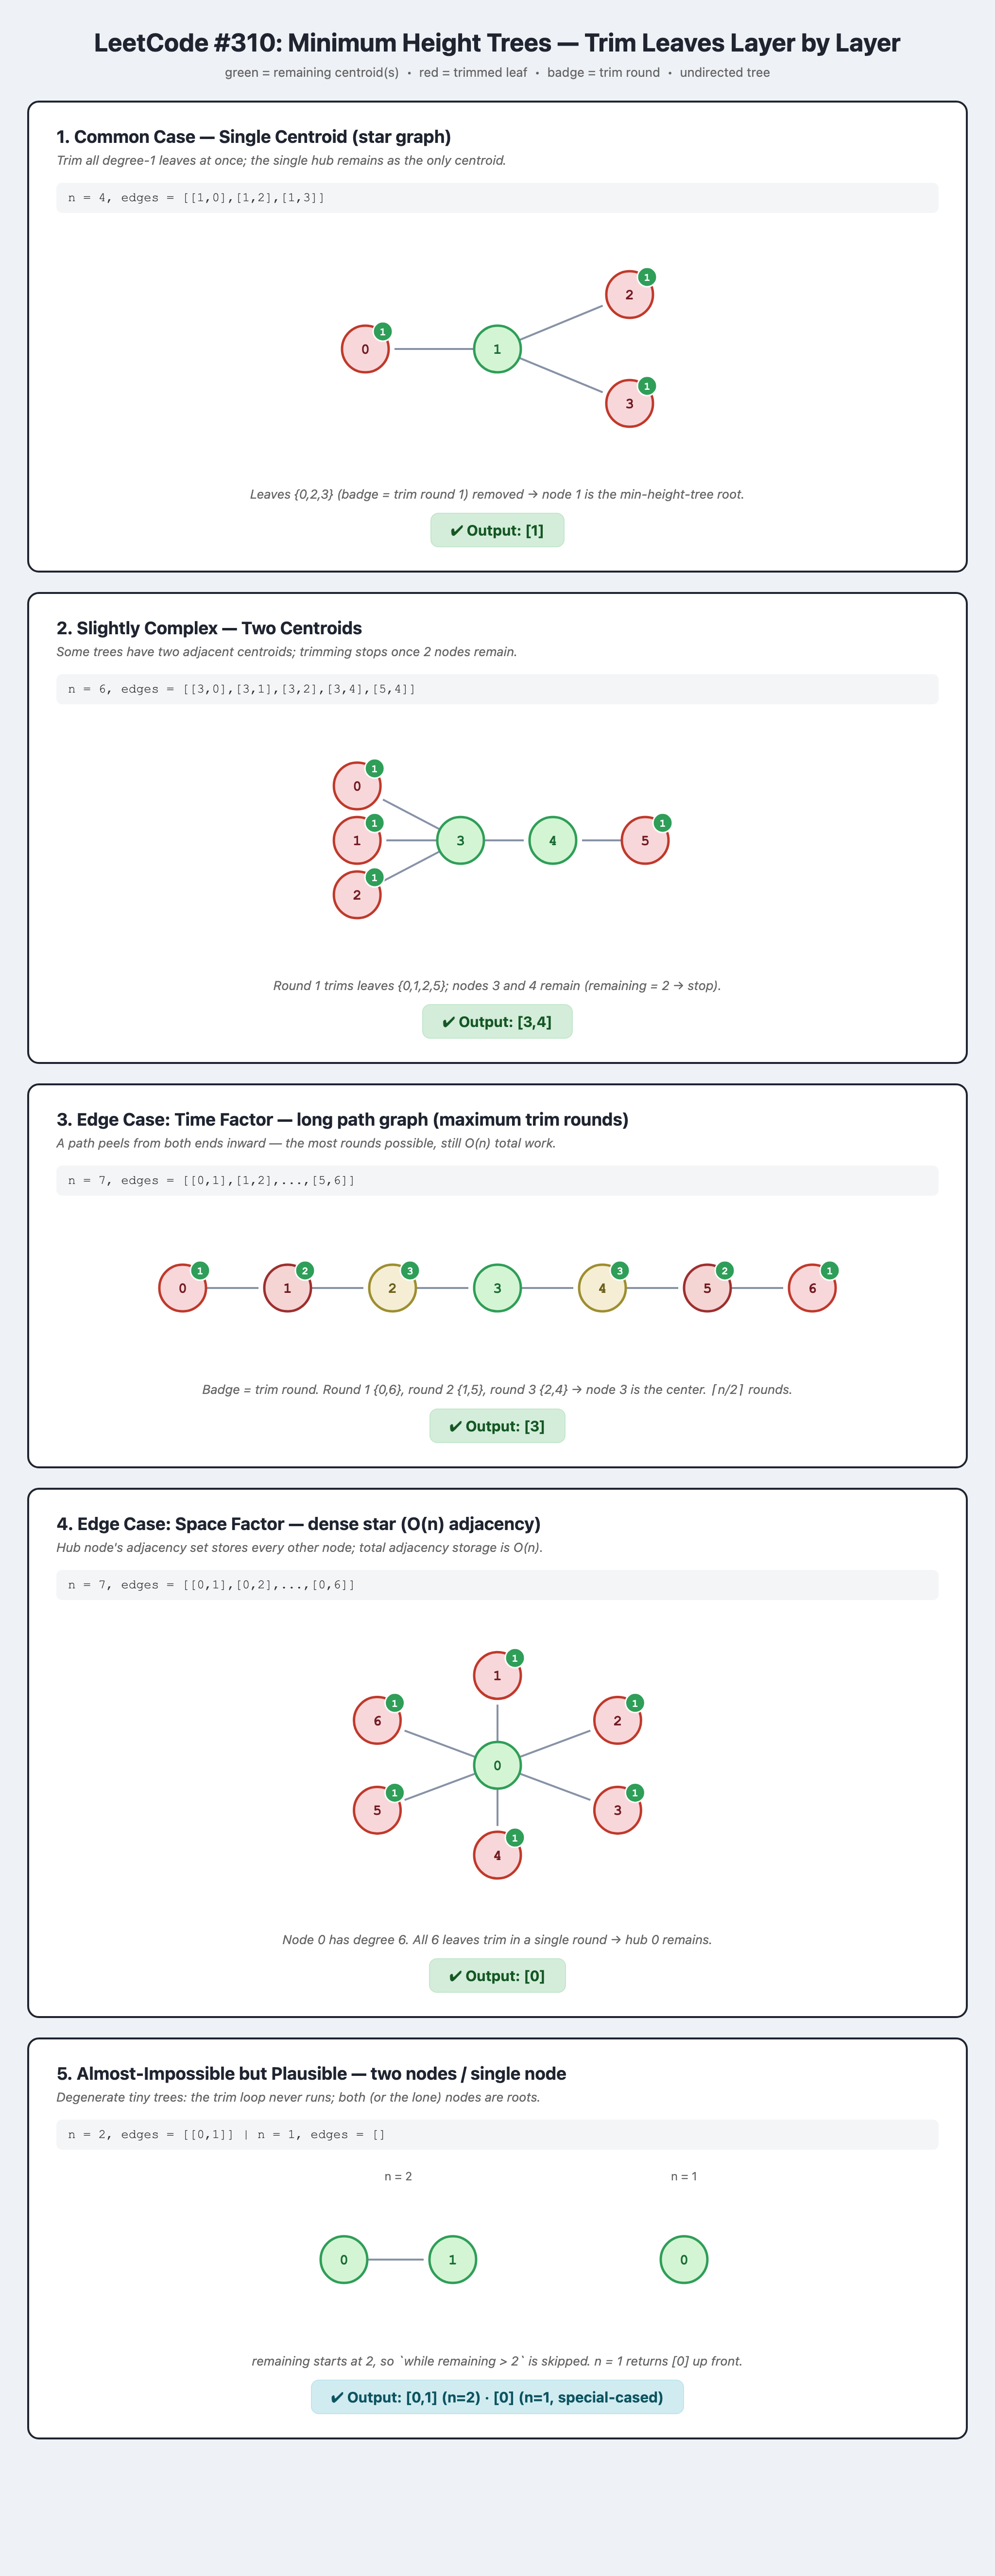